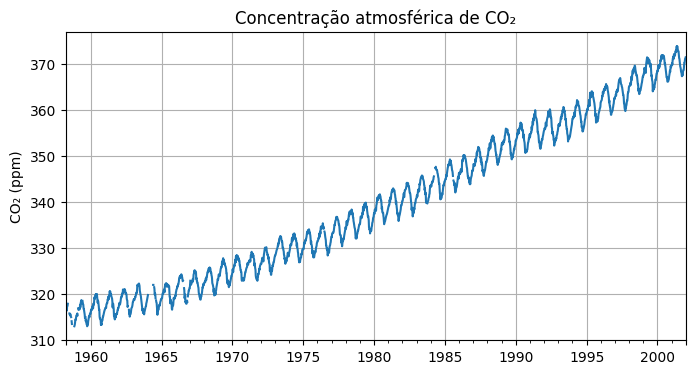

In [5]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

co2 = sm.datasets.co2.load_pandas().data["co2"]

co2.plot(figsize=(8, 4), title="Concentração atmosférica de CO₂")
plt.ylabel("CO₂ (ppm)")
plt.grid()
plt.show()

In [9]:
univariada = pd.DataFrame({"alvo_co2": co2})

for lag in [1, 2, 3, 12]:
    univariada[f"co2_lag_{lag}"] = co2.shift(lag)

univariada = univariada.dropna()

display(univariada.head())

,alvo_co2,co2_lag_1,co2_lag_2,co2_lag_3,co2_lag_12
1958-07-26,315.5,315.4,315.8,315.8,316.9
1958-08-09,315.1,315.6,315.5,315.4,317.5
1958-08-16,315.0,315.1,315.6,315.5,317.9
1958-11-29,314.0,313.5,313.2,313.0,313.5
1959-01-31,315.4,315.8,315.6,315.5,313.0


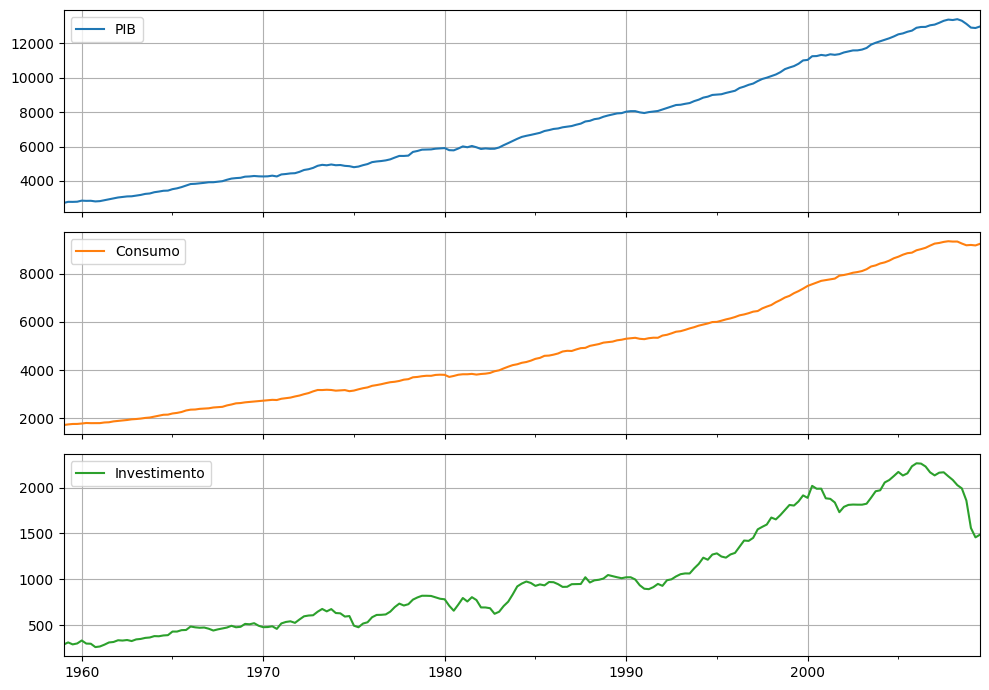

,PIB,Consumo,Investimento
1959-01-01,2710.349,1707.4,286.898
1959-04-01,2778.801,1733.7,310.859
1959-07-01,2775.488,1751.8,289.226
1959-10-01,2785.204,1753.7,299.356
1960-01-01,2847.699,1770.5,331.722


In [6]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

dados = sm.datasets.macrodata.load_pandas().data

# Índice temporal trimestral
dados.index = pd.PeriodIndex(
    [f"{int(a)}Q{int(t)}"
     for a, t in zip(dados["year"], dados["quarter"])],
    freq="Q"
).to_timestamp()

series = dados[["realgdp", "realcons", "realinv"]].copy()
series.columns = ["PIB", "Consumo", "Investimento"]

series.plot(subplots=True, figsize=(10, 7), grid=True)
plt.tight_layout()
plt.show()

display(series.head())

In [10]:
tabela = pd.DataFrame(index=series.index)
tabela["alvo_PIB"] = series["PIB"]

for coluna in series.columns:
    for lag in [1, 2, 3]:
        tabela[f"{coluna}_lag_{lag}"] = series[coluna].shift(lag)

tabela = tabela.dropna()

display(tabela.head())

,alvo_PIB,PIB_lag_1,PIB_lag_2,PIB_lag_3,Consumo_lag_1,Consumo_lag_2,Consumo_lag_3,Investimento_lag_1,Investimento_lag_2,Investimento_lag_3
1959-10-01,2785.204,2775.488,2778.801,2710.349,1751.8,1733.7,1707.4,289.226,310.859,286.898
1960-01-01,2847.699,2785.204,2775.488,2778.801,1753.7,1751.8,1733.7,299.356,289.226,310.859
1960-04-01,2834.390,2847.699,2785.204,2775.488,1770.5,1753.7,1751.8,331.722,299.356,289.226
1960-07-01,2839.022,2834.390,2847.699,2785.204,1792.9,1770.5,1753.7,298.152,331.722,299.356
1960-10-01,2802.616,2839.022,2834.390,2847.699,1785.8,1792.9,1770.5,296.375,298.152,331.722


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pib = series["PIB"].dropna().sort_index()

# Separação cronológica: 80% treino e 20% teste
corte = int(len(pib) * 0.8)
treino = pib.iloc[:corte]
teste = pib.iloc[corte:]

# Dados trimestrais: ciclo anual de 4 trimestres
s = 4
k = 4  # Janela da média dos últimos valores

historico = treino.tolist()
previsoes = []

for data, valor_real in teste.items():

    # 1. Ingênuo: último valor observado
    ingenuo = historico[-1]

    # 2. Sazonal ingênuo: mesmo trimestre do ano anterior
    sazonal = historico[-s]

    # 3. Média histórica: todos os valores disponíveis
    media_historica = np.mean(historico)

    # 4. Média dos últimos k valores
    media_movel = np.mean(historico[-k:])

    # 5. Drift: último valor + variação média por trimestre
    variacao_media = (
        (historico[-1] - historico[0]) / (len(historico) - 1)
    )
    drift = historico[-1] + variacao_media

    previsoes.append({
        "Ingênuo": ingenuo,
        "Sazonal ingênuo": sazonal,
        "Média histórica": media_historica,
        f"Média últimos {k}": media_movel,
        "Drift": drift
    })

    # Só depois de prever, incorporamos o valor observado
    historico.append(valor_real)

previsoes = pd.DataFrame(previsoes, index=teste.index)

resultado = previsoes.copy()
resultado.insert(0, "PIB real", teste)

display(resultado.head(10))

,PIB real,Ingênuo,Sazonal ingênuo,Média histórica,Média últimos 4,Drift
1999-07-01,10819.914,10684.049,10328.787,5948.151889,10530.39750,10733.575087
1999-10-01,11014.254,10819.914,10507.575,5978.040000,10653.17925,10869.973043
2000-01-01,11043.044,11014.254,10601.179,6008.748622,10779.84900,11065.198202
2000-04-01,11258.454,11043.044,10684.049,6039.259503,10890.31525,11093.853116
2000-07-01,11267.867,11258.454,10819.914,6070.700434,11033.91650,11310.260697
2000-10-01,11334.544,11267.867,11014.254,6101.821192,11145.90475,11319.418313
2001-01-01,11297.171,11334.544,11043.044,6132.968351,11225.97725,11386.185886
2001-04-01,11371.251,11297.171,11258.454,6163.525763,11289.50900,11348.283036
2001-07-01,11340.075,11371.251,11267.867,6194.159441,11317.70825,11422.498941
2001-10-01,11380.128,11340.075,11334.544,6224.252515,11335.76025,11390.838094


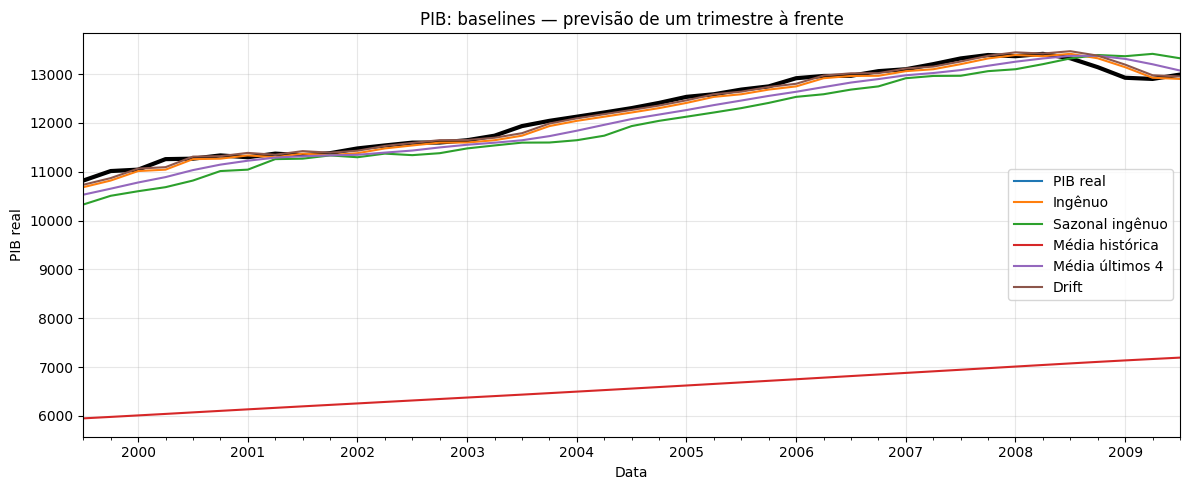

In [12]:
ax = resultado.plot(figsize=(12, 5), linewidth=1.5)

ax.lines[0].set_color("black")
ax.lines[0].set_linewidth(3)

plt.title("PIB: baselines — previsão de um trimestre à frente")
plt.xlabel("Data")
plt.ylabel("PIB real")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
metricas = []

for nome in previsoes.columns:
    erros = teste - previsoes[nome]

    metricas.append({
        "Modelo": nome,
        "MAE": np.abs(erros).mean(),
        "RMSE": np.sqrt((erros ** 2).mean())
    })

metricas = (
    pd.DataFrame(metricas)
    .set_index("Modelo")
    .sort_values("MAE")
)

display(metricas.round(2))

,MAE,RMSE
Modelo,,
Drift,61.63,86.14
Ingênuo,85.85,102.51
Média últimos 4,196.27,216.80
Sazonal ingênuo,315.00,342.06
Média histórica,5684.94,5703.61


In [22]:
from statsmodels.tsa.arima.model import ARIMA

# p=1: uma defasagem autorregressiva
# d=1: uma diferenciação
# q=1: uma defasagem dos erros
modelo = ARIMA(treino, order=(1, 1, 1))
ajuste = modelo.fit()

In [23]:
previsoes_arima = []

for data, valor_real in teste.items():

    # Prevê antes de consultar o valor real
    predicao = ajuste.forecast(steps=1)
    previsoes_arima.append(float(predicao.iloc[0]))

    # Incorpora a observação para prever o próximo trimestre
    nova_observacao = pd.Series(
        [valor_real],
        index=pd.DatetimeIndex([data]),
        name=treino.name
    )

    ajuste = ajuste.append(nova_observacao, refit=False)

previsoes["ARIMA(1,1,1)"] = previsoes_arima

In [24]:
metricas = []

for nome in previsoes.columns:
    erros = teste - previsoes[nome]

    metricas.append({
        "Modelo": nome,
        "MAE": np.abs(erros).mean(),
        "RMSE": np.sqrt((erros ** 2).mean())
    })

metricas = (
    pd.DataFrame(metricas)
    .set_index("Modelo")
    .sort_values("MAE")
)

display(metricas.round(2))

,MAE,RMSE
Modelo,,
"ARIMA(1,1,1)",60.78,78.00
Drift,61.63,86.14
Ingênuo,85.85,102.51
Média últimos 4,196.27,216.80
Sazonal ingênuo,315.00,342.06
Random Forest,1734.63,1912.93
Média histórica,5684.94,5703.61


In [25]:
from sklearn.ensemble import RandomForestRegressor

tabela = pd.DataFrame({"alvo": pib})

for lag in range(1, 5):
    tabela[f"lag_{lag}"] = pib.shift(lag)

# shift(1) impede que a média inclua o próprio alvo
tabela["media_4"] = pib.shift(1).rolling(window=4).mean()

tabela = tabela.dropna()

display(tabela.head())

,alvo,lag_1,lag_2,lag_3,lag_4,media_4
1960-01-01,2847.699,2785.204,2775.488,2778.801,2710.349,2762.46050
1960-04-01,2834.390,2847.699,2785.204,2775.488,2778.801,2796.79800
1960-07-01,2839.022,2834.390,2847.699,2785.204,2775.488,2810.69525
1960-10-01,2802.616,2839.022,2834.390,2847.699,2785.204,2826.57875
1961-01-01,2819.264,2802.616,2839.022,2834.390,2847.699,2830.93175


In [26]:
colunas = ["lag_1", "lag_2", "lag_3", "lag_4", "media_4"]

dados_treino = tabela.loc[tabela.index < teste.index[0]]
dados_teste = tabela.loc[teste.index]

X_treino = dados_treino[colunas]
y_treino = dados_treino["alvo"]

X_teste = dados_teste[colunas]
y_teste = dados_teste["alvo"]

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_treino, y_treino)

previsoes["Random Forest"] = rf.predict(X_teste)

In [29]:
from sklearn.metrics import r2_score

metricas = []

for nome in previsoes.columns:
    erros = teste - previsoes[nome]

    metricas.append({
        "Modelo": nome,
        "MAE": np.abs(erros).mean(),
        "RMSE": np.sqrt((erros ** 2).mean()),
        "R²": r2_score(teste, previsoes[nome])
    })

metricas = (
    pd.DataFrame(metricas)
    .set_index("Modelo")
    .sort_values("MAE")
)

display(metricas.round(3))

,MAE,RMSE,R²
Modelo,,,
"ARIMA(1,1,1)",60.782,78.005,0.991
Drift,61.629,86.136,0.989
Ingênuo,85.846,102.507,0.984
Média últimos 4,196.270,216.795,0.928
Sazonal ingênuo,315.005,342.063,0.820
Random Forest,1734.631,1912.926,-4.627
Média histórica,5684.945,5703.611,-49.022


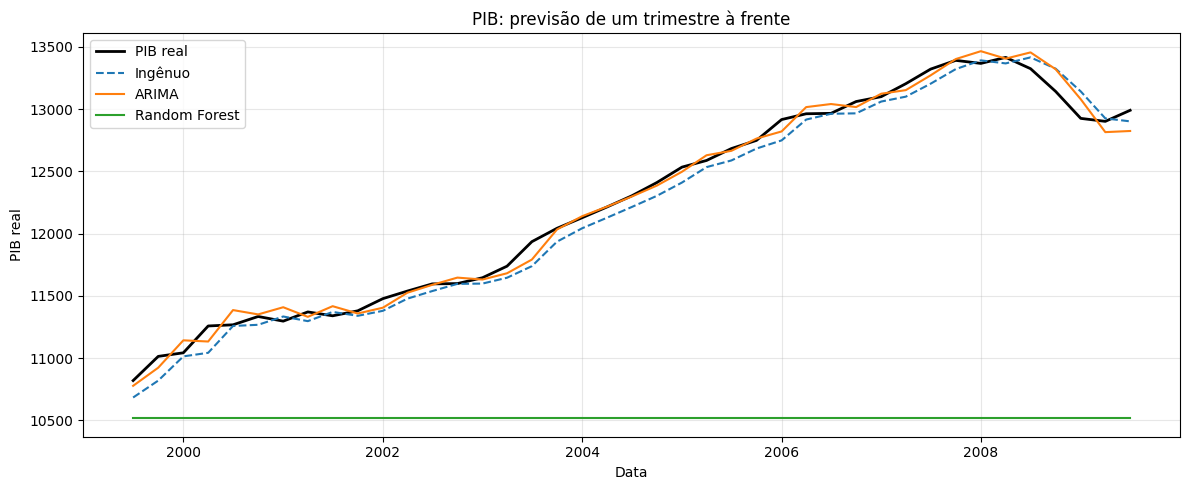

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(teste, label="PIB real", color="black", linewidth=2)
plt.plot(previsoes["Ingênuo"], label="Ingênuo", linestyle="--")
plt.plot(previsoes["ARIMA(1,1,1)"], label="ARIMA")
plt.plot(previsoes["Random Forest"], label="Random Forest")

plt.title("PIB: previsão de um trimestre à frente")
plt.xlabel("Data")
plt.ylabel("PIB real")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()